In [13]:

import sys
import json
import random
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import napari
from scipy.interpolate import griddata
from pathlib import Path



project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(Path.cwd().parent / 'scripts'))

sys.path.append(f"{project_root}src/")
# Import utilities
from utilities import KernelNN, KernelNN_subgraph, setup_device, get_output_affinities
from plot_utilities import rgb_scale

# Device setup
device = setup_device()
print(f'Using device: {device}')

ImportError: cannot import name 'rgb_scale' from 'plot_utilities' (/Volumes/T7-storage/NOFE/src/plot_utilities.py)

In [4]:
os.system("rsync -r springfield:~/new/NOFE/ERA5/trained_models/* ../trained_models/")

ssh: Could not resolve hostname springfield.uit.no: nodename nor servname provided, or not known
rsync: connection unexpectedly closed (0 bytes received so far) [Receiver]
rsync error: unexplained error (code 255) at io.c(232) [Receiver=3.4.1]


65280

In [5]:
# choose data
model_type = 'regular'


# ---------------------------------------------------------------------------
sys.path.append(f"{project_root}/ERA5/scripts/")
from utilities_era5 import ERA5_Graph_Generator as Data_Generator


# Paths
trained_models_path = project_root / 'ERA5' / 'trained_models' / model_type
training_logs_path = trained_models_path / 'logs'
data_path = project_root.parent / 'ERA5' / 'data'  # Adjust if needed

print('Available models:\n')
files = sorted(os.listdir(trained_models_path), reverse=True)

for i, f in enumerate(files):
    if Path(f).suffix == ".pth":
        print(f'[{i}] {f}')


using Device: mps
Available models:

[1] base-2026-03-12_t21-34-49.pth
[2] base-2026-03-12_t16-18-28.pth
[3] base-2026-02-06_t10-55-49.pth
[4] base-2026-02-03_t12-58-20.pth
[5] base-2026-02-03_t12-20-48.pth
[6] base-2026-02-03_t11-20-39.pth
[7] base-2026-02-03_t09-04-10.pth
[8] base-2026-02-02_t20-26-55.pth
[9] base-2026-01-29_t15-48-51.pth
[10] base-2026-01-28_t17-43-11.pth


## 2. Load Model and Configuration

In [6]:
# Set model ID
model_id = 'base-2026-03-12_t21-34-49'



# ---------------------------------------------------------------------------
if model_id.endswith('.pth'):
    model_id = model_id[:-4]

# Load full configuration (includes model, dataset, and training configs)
config_path = f'{training_logs_path}/configs/{model_id}.json'
with open(config_path, 'r') as f:
    config = json.load(f)

# Load loss records
loss_df = pd.read_csv(f'{training_logs_path}/loss_records/{model_id}.csv')

print('Configuration:')
for key, value in config.items():
    print(f'  {key}: {value}')

print(f'\Training completed {len(loss_df)} epochs')
print(f'Final training loss: {loss_df["loss"].iloc[-1]:.4f}')
print(f'Final validation loss: {loss_df["val_loss"].iloc[-1]:.4f}')

Configuration:
  mode: regular
  dataset_id: base
  model_id: base
  epochs: 20
  learning_rate: 0.0001
  scheduler_step: 4
  scheduler_gamma: 0.8
  width: 32
  ker_width: 32
  depth: 4
  node_features: 14
  edge_attr: 7
  out_width: 3
  data_folder_path: ../data/
  dataset_save_path: ../datasets/regular/
  lat_min: 30
  lat_max: 70
  lon_min: -10
  lon_max: 30
  N: 5000
  k: 10
  perplexity: 10
  sampling_method: random
  train_date_start_end: ['2018-01-01', '2018-12-31']
  test_date_start_end: ['2019-01-01', '2019-01-31']
  train_samples_per_date: 50
  test_samples_per_date: 20
  feature_mode: channel_and_position
  vars: ['w', 'v', 'z', 'q', 'r', 't', 'd', 'o3', 'pv', 'u', 'vo']
\Training completed 21 epochs
Final training loss: 0.1230
Final validation loss: 0.1236


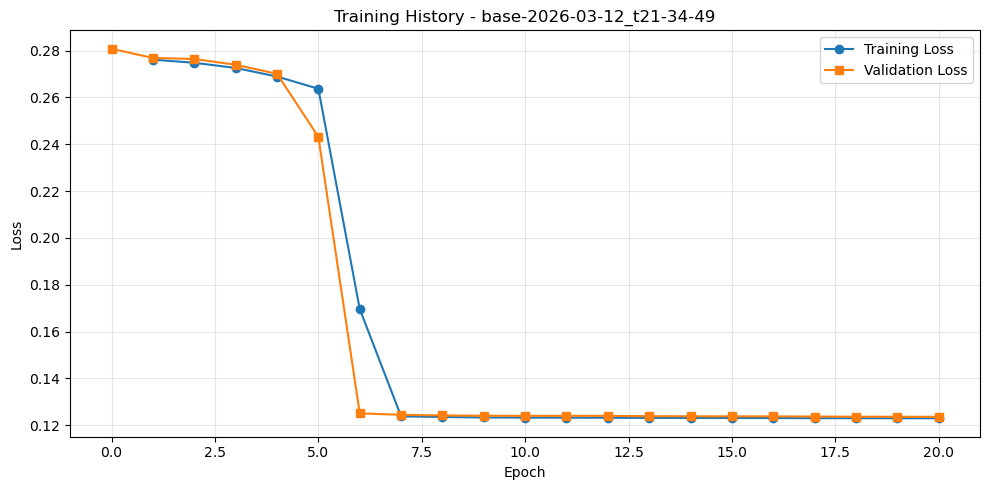

In [7]:
# Plot training history
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(loss_df['epoch'], loss_df['loss'], label='Training Loss', marker='o')
ax.plot(loss_df['epoch'], loss_df['val_loss'], label='Validation Loss', marker='s')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title(f'Training History - {model_id}')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
lat_min = config["lat_min"]
lat_max = config["lat_max"]
lon_min = config["lon_min"]
lon_max = config["lon_max"]
N = 5000 #config["N"]
k = config["k"]
perplexity = config["perplexity"]
sampling_method = config["sampling_method"]
train_date_start_end = config["train_date_start_end"]
test_date_start_end = config["test_date_start_end"]
train_samples_per_date = config["train_samples_per_date"]
test_samples_per_date = config["test_samples_per_date"]
feature_mode = config["feature_mode"]
vars = config["vars"]


In [9]:
model = KernelNN(
    width=config['width'],
    ker_width=config['ker_width'],
    depth=config['depth'],
    ker_in=config['edge_attr'],
    in_width=config['node_features'],
    out_width=config['out_width']
).to(device)

# Load trained weights
model_path = f'{trained_models_path}/{model_id}.pth'
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

print(f'Model loaded: {model_id}')
print(f'Total parameters: {sum(p.numel() for p in model.parameters()):,}')

Model loaded: base-2026-03-12_t21-34-49
Total parameters: 36,739


## 3. Create New Sample

Use the same functionality as dataset creation to generate a single sample.

In [11]:
date = "2019-04-01"


bbox = lon_min, lat_min, lon_max, lat_max
Generator = Data_Generator(data_path)
Generator.load_data(bbox=bbox, vars=vars, filename=f'{date}.nc')


print('generate data')
graph = Generator.sample_graph(N=N, k=k, perplexity=perplexity, sampling_method=sampling_method, gen_feature_mode=feature_mode)
sample = graph.to(device)


print('predict results')
output = model(sample).detach().cpu().numpy()

generate data
predict results


In [12]:
# compare to input:
inputs = sample.normed_values.cpu().numpy()

locations = pd.DataFrame({"lat": sample.meta.gps[:,0], "lon": sample.meta.gps[:,1]})

input_obs = pd.DataFrame(
    {
        "x1": inputs[:, 0],
        "x2": inputs[:, 1],
        "x3": inputs[:, 2],
    }
)
input_obs = pd.concat([locations, input_obs], axis=1)

figsize = (10, 10)
fig = rgb(input_obs, figsize=figsize)

NameError: name 'rgb' is not defined